# Лабораторна робота № 5–6: нейронна мережа і регуляризація

**Мета:** самостійно реалізувати повнозв’язну нейронну мережу для класифікації FashionMNIST, перевірити backpropagation і дослідити, як регуляризація змінює ваги, sparsity, кількість dead neurons та якість.

Основна модель, прямий прохід, функція втрат, зворотне поширення помилки й SGD реалізовані на NumPy. Для контрольованої швидкості дозволеною методичкою є однакова стратифікована підмножина для всіх запусків; тестова вибірка залишається поза вибором методу.

## 0. Налаштування середовища та відтворюваність

Ноутбук завантажує FashionMNIST через OpenML (data ID 40996). У середовищі лабораторної мають бути встановлені `numpy`, `pandas`, `matplotlib`, `scikit-learn` та `liac-arff`; нижче фіксуємо seed і глобальні налаштування експерименту.

In [1]:
import json
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits

SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
threadpool_limits(limits=2)
pd.set_option('display.max_columns', 20)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True

print('Seed:', SEED)

Seed: 42


## 1. FashionMNIST: завантаження, розбиття та підготовка

Завантажуємо зображення розміру 28×28, перетворюємо їх на вектори з 784 пікселів і нормалізуємо в [0, 1]. Спочатку робимо стратифіковані Train/Validation/Test розбиття, потім беремо однакові фіксовані підмножини для всіх регуляризаційних експериментів.

In [2]:
fashion = fetch_openml(data_id=40996, as_frame=False, parser='liac-arff')
X_all = np.asarray(fashion.data, dtype=np.float32).reshape(-1, 784) / 255.0
y_all = np.asarray(fashion.target, dtype=np.int64)
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_all, y_all, test_size=0.10, stratify=y_all, random_state=SEED
)
X_train_full, X_val_full, y_train_full, y_val_full = train_test_split(
    X_train_full, y_train_full, test_size=1 / 9, stratify=y_train_full,
    random_state=SEED + 1
)

N_TRAIN, N_VAL, N_TEST = 5000, 1000, 1000
X_train, _, y_train, _ = train_test_split(
    X_train_full, y_train_full, train_size=N_TRAIN, stratify=y_train_full,
    random_state=SEED + 2
)
X_val, _, y_val, _ = train_test_split(
    X_val_full, y_val_full, train_size=N_VAL, stratify=y_val_full,
    random_state=SEED + 3
)
X_test, _, y_test, _ = train_test_split(
    X_test_full, y_test_full, train_size=N_TEST, stratify=y_test_full,
    random_state=SEED + 4
)

print(f'Повний FashionMNIST: {X_all.shape[0]:,} зображень, {X_all.shape[1]} ознак, {len(class_names)} класів')
print(f'Експерименти: Train={len(y_train)}, Validation={len(y_val)}, Test={len(y_test)}')
print(f'Діапазон пікселів після нормалізації: [{X_train.min():.1f}, {X_train.max():.1f}]')

class_distribution = pd.DataFrame({
     'Train': pd.Series(y_train).value_counts(normalize=True).sort_index().to_numpy() * 100,
     'Validation': pd.Series(y_val).value_counts(normalize=True).sort_index().to_numpy() * 100,
     'Test': pd.Series(y_test).value_counts(normalize=True).sort_index().to_numpy() * 100,
}, index=class_names).round(2)
class_distribution.index.name = 'Клас'
class_distribution

Повний FashionMNIST: 70,000 зображень, 784 ознак, 10 класів
Експерименти: Train=5000, Validation=1000, Test=1000
Діапазон пікселів після нормалізації: [0.0, 1.0]


,Train,Validation,Test
Клас,,,
T-shirt/top,10.0,10.0,10.0
Trouser,10.0,10.0,10.0
Pullover,10.0,10.0,10.0
Dress,10.0,10.0,10.0
Coat,10.0,10.0,10.0
Sandal,10.0,10.0,10.0
Shirt,10.0,10.0,10.0
Sneaker,10.0,10.0,10.0
Bag,10.0,10.0,10.0


**Висновок до таблиці розподілу класів.** Частки класів у трьох підмножинах мають бути близькими завдяки стратифікації. Це робить порівняння регуляризацій чесним: відмінності в accuracy не пояснюються випадковою зміною складу класів.

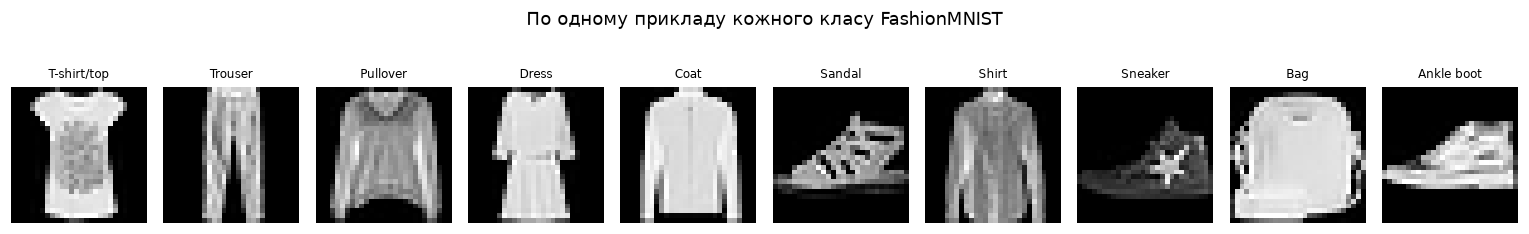

In [3]:
fig, axes = plt.subplots(1, 10, figsize=(14, 2.4))
for label, ax in enumerate(axes):
    idx = np.flatnonzero(y_train == label)[0]
    ax.imshow(X_train[idx].reshape(28, 28), cmap='gray')
    ax.set_title(class_names[label], fontsize=8)
    ax.axis('off')
fig.suptitle('По одному прикладу кожного класу FashionMNIST')
plt.tight_layout()
plt.show()

**Висновок до рисунка.** На рисунку наведено по одному прикладу кожної категорії. Частина одягу має подібні силуети (наприклад, сорочка, пальто й пуловер), тому класифікатору потрібні нелінійні приховані шари; подібні класи можуть лишатися джерелом помилок навіть після регуляризації.

## 2. Архітектура та NumPy-реалізація MLP

Використовуємо чотири приховані шари з ReLU і вихідний Softmax-шар. Ваги ініціалізуються методом He; крос-ентропія та backpropagation обчислюються матричними операціями без автоматичного диференціювання.

In [4]:
ARCHITECTURE = [784, 128, 64, 32, 16, 10]
HIDDEN_LAYER_COUNT = len(ARCHITECTURE) - 2
N_CLASSES = 10

class NumpyMLP:
    """Повнозв'язна мережа: ReLU у прихованих шарах, Softmax на виході."""

    def __init__(self, architecture, seed=SEED, l1=0.0, l2=0.0,
                 dropout=0.0, weight_clip=None, grad_clip=None):
        self.architecture = list(architecture)
        self.l1 = float(l1)
        self.l2 = float(l2)
        self.dropout = float(dropout)
        self.weight_clip = weight_clip
        self.grad_clip = grad_clip
        self.init_seed = int(seed)
        init_rng = np.random.default_rng(seed)
        self.train_rng = np.random.default_rng(seed + 1)
        self.dropout_rng = np.random.default_rng(seed + 2)
        self.weights = []
        self.biases = []
        for fan_in, fan_out in zip(self.architecture[:-1], self.architecture[1:]):
            # Ініціалізація He зберігає масштаб сигналу в мережі з ReLU.
            self.weights.append(init_rng.normal(0.0, np.sqrt(2.0 / fan_in), (fan_in, fan_out)))
            self.biases.append(np.zeros((1, fan_out), dtype=np.float64))
        self.grad_clip_events = 0
        self.weight_clip_events = 0

    def forward(self, X, training=False):
        self.activations = [np.asarray(X, dtype=np.float64)]
        self.z_values = []
        self.dropout_masks = []
        A = self.activations[0]
        for layer in range(len(self.weights) - 1):
            Z = A @ self.weights[layer] + self.biases[layer]
            A = np.maximum(0.0, Z)
            mask = None
            if training and self.dropout > 0:
                # Інверсний Dropout зберігає математичне сподівання активацій.
                mask = (self.dropout_rng.random(A.shape) >= self.dropout) / (1.0 - self.dropout)
                A = A * mask
            self.z_values.append(Z)
            self.dropout_masks.append(mask)
            self.activations.append(A)

        logits = A @ self.weights[-1] + self.biases[-1]
        logits = logits - np.max(logits, axis=1, keepdims=True)
        exp_logits = np.exp(logits)
        probabilities = exp_logits / np.sum(exp_logits, axis=1, keepdims=True)
        self.z_values.append(logits)
        self.activations.append(probabilities)
        return probabilities

    def loss(self, X, y, include_regularization=False):
        probabilities = self.forward(X, training=False)
        ce = -np.mean(np.log(np.clip(probabilities[np.arange(len(y)), y], 1e-15, 1.0)))
        if include_regularization:
            weights = np.concatenate([W.ravel() for W in self.weights])
            ce += self.l1 * np.sum(np.abs(weights))
            ce += 0.5 * self.l2 * np.sum(weights ** 2)
        return float(ce)

    def backward(self, y):
        n = len(y)
        delta = self.activations[-1].copy()
        delta[np.arange(n), y] -= 1.0
        delta /= n
        grads_W = [None] * len(self.weights)
        grads_b = [None] * len(self.biases)
        for layer in reversed(range(len(self.weights))):
            grads_W[layer] = self.activations[layer].T @ delta
            grads_b[layer] = np.sum(delta, axis=0, keepdims=True)
            if layer > 0:
                delta = delta @ self.weights[layer].T
                delta *= (self.z_values[layer - 1] > 0)
                mask = self.dropout_masks[layer - 1]
                if mask is not None:
                    delta *= mask
        if self.l1:
            grads_W = [g + self.l1 * np.sign(W) for g, W in zip(grads_W, self.weights)]
        if self.l2:
            grads_W = [g + self.l2 * W for g, W in zip(grads_W, self.weights)]
        return grads_W, grads_b

    def predict_proba(self, X):
        return self.forward(X, training=False)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

    def train_batch(self, X, y, learning_rate):
        self.forward(X, training=True)
        grads_W, grads_b = self.backward(y)
        if self.grad_clip is not None:
            norm = np.sqrt(sum(np.sum(g ** 2) for g in grads_W + grads_b))
            if norm > self.grad_clip:
                scale = self.grad_clip / (norm + 1e-12)
                grads_W = [g * scale for g in grads_W]
                grads_b = [g * scale for g in grads_b]
                self.grad_clip_events += 1
        for i in range(len(self.weights)):
            self.weights[i] -= learning_rate * grads_W[i]
            self.biases[i] -= learning_rate * grads_b[i]
            if self.weight_clip is not None:
                before = self.weights[i].copy()
                np.clip(self.weights[i], -self.weight_clip, self.weight_clip, out=self.weights[i])
                self.weight_clip_events += int(np.count_nonzero(before != self.weights[i]))

    def fit(self, X, y, X_val, y_val, epochs=8, batch_size=128, learning_rate=0.06):
        history = {'train_loss': [], 'val_loss': [], 'train_accuracy': [], 'val_accuracy': []}
        for epoch in range(epochs):
            order = self.train_rng.permutation(len(y))
            for start in range(0, len(order), batch_size):
                idx = order[start:start + batch_size]
                self.train_batch(X[idx], y[idx], learning_rate)
            history['train_loss'].append(self.loss(X, y, include_regularization=True))
            history['val_loss'].append(self.loss(X_val, y_val))
            history['train_accuracy'].append(np.mean(self.predict(X) == y))
            history['val_accuracy'].append(np.mean(self.predict(X_val) == y_val))
        return history

    def save(self, path):
        payload = {
            'architecture': np.asarray(self.architecture, dtype=np.int64),
            'config': np.asarray(json.dumps({
                'l1': self.l1, 'l2': self.l2, 'dropout': self.dropout,
                'weight_clip': self.weight_clip, 'grad_clip': self.grad_clip,
                'init_seed': self.init_seed,
            })),
        }
        payload.update({f'W_{i}': W for i, W in enumerate(self.weights)})
        payload.update({f'b_{i}': b for i, b in enumerate(self.biases)})
        np.savez_compressed(path, **payload)

    @classmethod
    def load(cls, path):
        with np.load(path, allow_pickle=False) as data:
            architecture = data['architecture'].tolist()
            config = json.loads(str(data['config'].item()))
            config['seed'] = config.pop('init_seed')
            model = cls(architecture, **config)
            model.weights = [data[f'W_{i}'].copy() for i in range(len(architecture) - 1)]
            model.biases = [data[f'b_{i}'].copy() for i in range(len(architecture) - 1)]
        return model

print('Архітектура:', ARCHITECTURE, '| прихованих шарів:', HIDDEN_LAYER_COUNT)
print('Параметрів:', sum(W.size + b.size for W, b in zip(
    NumpyMLP(ARCHITECTURE).weights, NumpyMLP(ARCHITECTURE).biases)))

Архітектура: [784, 128, 64, 32, 16, 10] | прихованих шарів: 4
Параметрів: 111514


**Пояснення архітектури.** Матриця ваг кожного шару має розмір `(входи, виходи)`, а зміщення — `(1, виходи)`. У `backward` похідна Softmax разом із cross-entropy спрощується до `P − Y`; далі градієнт послідовно проходить крізь ваги та маску похідної ReLU. Маска dropout у зворотному проході та сама, що була використана в прямому.

## 3. Чисельна перевірка backpropagation

Для кількох параметрів порівнюємо аналітичну похідну з центральною скінченною різницею. Перевірка виконується на невеликому батчі без Dropout і регуляризації, щоб ізолювати правильність градієнта основної мережі.

In [5]:
def numerical_gradient_check(model, X, y, parameters, eps=1e-5):
    model.forward(X, training=False)
    grads_W, grads_b = model.backward(y)
    rows = []
    for kind, layer, index in parameters:
        array = model.weights[layer] if kind == 'W' else model.biases[layer]
        analytic = grads_W[layer][index] if kind == 'W' else grads_b[layer][index]
        original = array[index]
        array[index] = original + eps
        loss_plus = model.loss(X, y)
        array[index] = original - eps
        loss_minus = model.loss(X, y)
        array[index] = original
        numeric = (loss_plus - loss_minus) / (2 * eps)
        relative_error = abs(analytic - numeric) / max(1e-8, abs(analytic) + abs(numeric))
        rows.append({'Параметр': f'{kind}[{layer}]{index}', 'Аналітичний': analytic,
                     'Чисельний': numeric, 'Відносна похибка': relative_error})
    return pd.DataFrame(rows)

check_model = NumpyMLP(ARCHITECTURE, seed=SEED)
check_model.forward(X_train[:8], training=False)
probe_grads_W, probe_grads_b = check_model.backward(y_train[:8])
check_params = [
    ('W', layer, tuple(map(int, np.unravel_index(
        np.argmax(np.abs(probe_grads_W[layer])), probe_grads_W[layer].shape))))
    for layer in [0, 2, 4]
]
check_params.append(('b', 3, (0, int(np.argmax(np.abs(probe_grads_b[3][0]))))))
grad_check = numerical_gradient_check(check_model, X_train[:8], y_train[:8], check_params)
grad_check.round(10)

,Параметр,Аналітичний,Чисельний,Відносна похибка
0,"W[0](437, 15)",-0.104933,-0.104933,0.0
1,"W[2](42, 9)",0.242354,0.242354,0.0
2,"W[4](1, 3)",-0.365801,-0.365801,0.0
3,"b[3](0, 3)",0.302407,0.302407,0.0


**Висновок до таблиці перевірки градієнтів.** Чисельні та аналітичні значення мають узгоджуватися в межах похибки скінченної різниці. Мала відносна похибка на параметрах різних шарів підтверджує коректність ланцюгового правила до навчальних експериментів.

In [6]:
MAX_GRAD_ERROR = float(grad_check['Відносна похибка'].max())
print(f'Найбільша відносна похибка: {MAX_GRAD_ERROR:.3e}')
assert MAX_GRAD_ERROR < 1e-5, 'Перевірка градієнтів не пройдена'

Найбільша відносна похибка: 1.561e-11


## 4. Навчання базової моделі та перевірка серіалізації

 Базова мережа навчається міні-батчевим SGD без регуляризації. Навчальна швидкість `0.01` зафіксована спільно для всіх запусків після перевірки стійкості навчання: завеликий крок спричиняв коливання втрат. Після базового навчання збережемо архітектуру, параметри конфігурації, ваги й зміщення у NPZ-файл, створимо новий екземпляр і перевіримо збіг прогнозів.

In [7]:
EPOCHS = 12
BATCH_SIZE = 128
LEARNING_RATE = 0.01

initial_model = NumpyMLP(ARCHITECTURE, seed=SEED)
INITIAL_WEIGHTS = [W.copy() for W in initial_model.weights]

baseline_model = NumpyMLP(ARCHITECTURE, seed=SEED)
baseline_history = baseline_model.fit(
    X_train, y_train, X_val, y_val, epochs=EPOCHS,
    batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE
)

with tempfile.TemporaryDirectory() as tmp_dir:
    weights_path = Path(tmp_dir) / 'fashion_mlp_weights.npz'
    baseline_model.save(weights_path)
    restored_model = NumpyMLP.load(weights_path)
    sample_prob_original = baseline_model.predict_proba(X_val[:64])
    sample_prob_restored = restored_model.predict_proba(X_val[:64])
    max_restore_error = float(np.max(np.abs(sample_prob_original - sample_prob_restored)))
    same_classes = bool(np.array_equal(baseline_model.predict(X_val[:64]),
                                       restored_model.predict(X_val[:64])))

print(f'Max |P_original - P_restored| = {max_restore_error:.3e}')
print('Передбачені класи збігаються:', same_classes)
assert max_restore_error < 1e-7 and same_classes

Max |P_original - P_restored| = 0.000e+00
Передбачені класи збігаються: True


**Висновок до перевірки збереження.** Похибка прогнозів після завантаження має бути меншою за `10⁻⁷`, а класи — ідентичними. Це перевіряє не лише запис ваг, а й відновлення архітектури та відповідності матриць конкретним шарам.

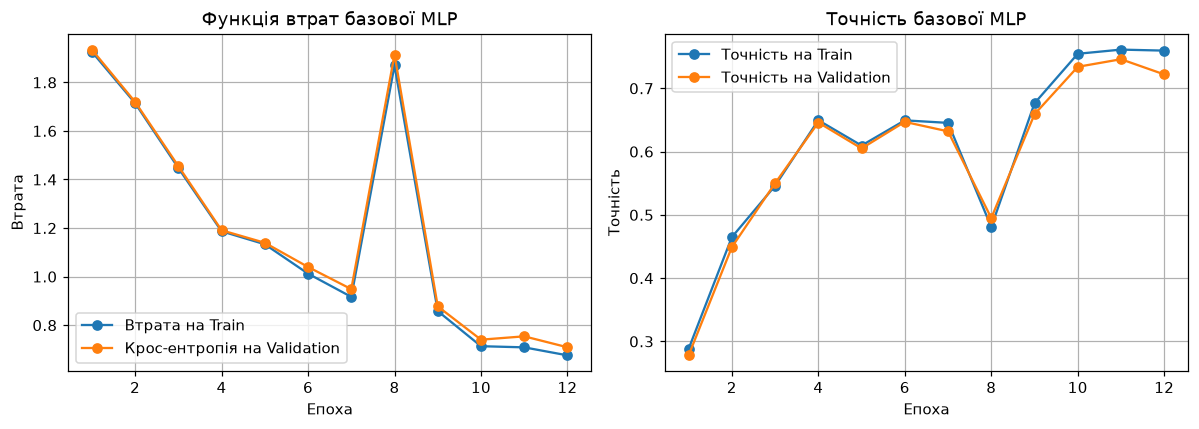

Фінальна точність на Validation: 0.7220; cross-entropy: 0.7089


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
epochs_axis = np.arange(1, EPOCHS + 1)
axes[0].plot(epochs_axis, baseline_history['train_loss'], marker='o', label='Втрата на Train')
axes[0].plot(epochs_axis, baseline_history['val_loss'], marker='o', label='Крос-ентропія на Validation')
axes[0].set_title('Функція втрат базової MLP')
axes[0].set_xlabel('Епоха'); axes[0].set_ylabel('Втрата'); axes[0].legend()
axes[1].plot(epochs_axis, baseline_history['train_accuracy'], marker='o', label='Точність на Train')
axes[1].plot(epochs_axis, baseline_history['val_accuracy'], marker='o', label='Точність на Validation')
axes[1].set_title('Точність базової MLP')
axes[1].set_xlabel('Епоха'); axes[1].set_ylabel('Точність'); axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Фінальна точність на Validation: {baseline_history['val_accuracy'][-1]:.4f}; "
      f"cross-entropy: {baseline_history['val_loss'][-1]:.4f}")

**Висновок до графіків навчання.** Криві показують, як змінюються помилка й точність на Train та Validation. Якщо навчальна якість зростає помітно швидше за валідаційну або validation loss знову зростає, це ознака перенавчання; саме базова модель задає орієнтир для оцінювання регуляризації.

## 5. Діагностика dead neurons, sparsity та метрик

Dead neuron визначаємо лише в inference-режимі: прихований нейрон є мертвим, якщо його передактивація `Z` не додатна для жодного прикладу Train. Sparsity рахуємо як частку ваг із `|w| < 0.01`; bias у це визначення не включаємо.

In [9]:
def evaluate(model, X, y):
    probabilities = model.predict_proba(X)
    return {
        'accuracy': float(np.mean(np.argmax(probabilities, axis=1) == y)),
        'loss': float(-np.mean(np.log(np.clip(probabilities[np.arange(len(y)), y], 1e-15, 1.0)))),
    }

def dead_neurons_by_layer(model, X):
    model.forward(X, training=False)
    # Нульова ReLU-активація для всіх прикладів еквівалентна max(Z_j) <= 0.
    dead = [int(np.sum(np.max(Z, axis=0) <= 0)) for Z in model.z_values[:-1]]
    totals = [W.shape[1] for W in model.weights[:-1]]
    return dead, totals

def weight_diagnostics(model, near_zero_threshold=0.01, clip_bound=1.0):
    flat = np.concatenate([W.ravel() for W in model.weights])
    return {
        'sparsity_pct': float(np.mean(np.abs(flat) < near_zero_threshold) * 100),
        'dead_weights_pct': float(np.sum(np.abs(flat) < 1e-12) / flat.size * 100),
        'at_clip_bound': int(np.sum(np.isclose(np.abs(flat), clip_bound, atol=1e-10))),
        'weight_count': int(flat.size),
    }

base_dead, layer_sizes = dead_neurons_by_layer(baseline_model, X_train)
base_diag = weight_diagnostics(baseline_model)
print('Базова модель — мертві нейрони за прихованими шарами:', base_dead)
print(f"Базова sparsity (|w| < 0.01): {base_diag['sparsity_pct']:.2f}%")

Базова модель — мертві нейрони за прихованими шарами: [0, 3, 4, 1]
Базова sparsity (|w| < 0.01): 14.81%


**Інтерпретація діагностики.** Sparsity ваг і dead neurons — різні властивості: малі ваги можуть бути розподілені між багатьма активними нейронами, а мертвий нейрон визначається сукупністю активацій на всій навчальній підмножині. Кількість dead neurons надалі наведемо окремо для кожного прихованого шару.

## 6. Експерименти з регуляризацією

Для всіх методів незмінні архітектура, seed, дані, learning rate, batch size й число епох. Варіюється лише відповідне обмеження. Перебираємо два коефіцієнти L1, два L2 та два пороги gradient clipping; Dropout тестуємо при `p ∈ {0.1, 0.3, 0.5}`, як вимагає методичка.

In [10]:
EXPERIMENTS = [
    ('Без регуляризації', {}),
    ('L2 (lambda=1e-4)', {'l2': 1e-4}),
    ('L2 (lambda=5e-4)', {'l2': 5e-4}),
    ('L1 (lambda=1e-5)', {'l1': 1e-5}),
    ('L1 (lambda=5e-5)', {'l1': 5e-5}),
    ('Dropout (p=0.1)', {'dropout': 0.1}),
    ('Dropout (p=0.3)', {'dropout': 0.3}),
    ('Dropout (p=0.5)', {'dropout': 0.5}),
    ('Weight clipping [-1, 1]', {'weight_clip': 1.0}),
    ('Gradient clipping (c=0.5)', {'grad_clip': 0.5}),
    ('Gradient clipping (c=2.0)', {'grad_clip': 2.0}),
    ('L2 (1e-4) + Dropout (p=0.2)', {'l2': 1e-4, 'dropout': 0.2}),
]

models = {'Без регуляризації': baseline_model}
histories = {'Без регуляризації': baseline_history}
for name, config in EXPERIMENTS[1:]:
    print(f'Навчання: {name}')
    model = NumpyMLP(ARCHITECTURE, seed=SEED, **config)
    history = model.fit(X_train, y_train, X_val, y_val, epochs=EPOCHS,
                        batch_size=BATCH_SIZE, learning_rate=LEARNING_RATE)
    models[name] = model
    histories[name] = history

print(f'Готово: {len(models)} моделей, кожна навчена на тих самих підмножинах.')

Навчання: L2 (lambda=1e-4)


Навчання: L2 (lambda=5e-4)


Навчання: L1 (lambda=1e-5)


Навчання: L1 (lambda=5e-5)


Навчання: Dropout (p=0.1)


Навчання: Dropout (p=0.3)


... (2 outputs left out)

Навчання: Gradient clipping (c=0.5)


Навчання: Gradient clipping (c=2.0)


Навчання: L2 (1e-4) + Dropout (p=0.2)


Готово: 12 моделей, кожна навчена на тих самих підмножинах.


## 7. Порівняння метрик і dead neurons

Порівнюємо validation accuracy та cross-entropy, aggregate dead-neuron share, sparsity і кількість ваг на межах clipping. Додатково формуємо таблицю dead neurons по кожному прихованому шару; це дає змогу побачити, чи метод концентрує проблему в конкретному рівні.

In [11]:
summary_rows = []
dead_rows = []
for name, model in models.items():
    val_metrics = evaluate(model, X_val, y_val)
    dead, sizes = dead_neurons_by_layer(model, X_train)
    diag = weight_diagnostics(model)
    summary_rows.append({
        'Метод': name,
        'Dead neurons, %': 100 * sum(dead) / sum(sizes),
        'Sparsity (|w|<0.01), %': diag['sparsity_pct'],
        'Validation accuracy': val_metrics['accuracy'],
        'Validation loss': val_metrics['loss'],
        'Ваг на межі ±1': diag['at_clip_bound'],
        'Кліпованих градієнтних батчів': model.grad_clip_events,
    })
    row = {'Метод': name}
    row.update({f'Шар {i + 1} ({sizes[i]} нейронів)': f'{dead[i]} ({100 * dead[i] / sizes[i]:.1f}%)'
                for i in range(len(dead))})
    dead_rows.append(row)

results_df = pd.DataFrame(summary_rows).set_index('Метод')
dead_df = pd.DataFrame(dead_rows).set_index('Метод')
display(results_df.sort_values('Validation accuracy', ascending=False).round(4))
display(dead_df)

,"Dead neurons, %","Sparsity (|w|<0.01), %",Validation accuracy,Validation loss,Ваг на межі ±1,Кліпованих градієнтних батчів
Метод,,,,,,
Gradient clipping (c=2.0),3.7500,14.8098,0.746,0.6897,0,206
"Weight clipping [-1, 1]",2.9167,14.7918,0.742,0.6861,1,0
L1 (lambda=5e-5),3.3333,15.1702,0.734,0.6962,0,0
L2 (lambda=1e-4),3.3333,14.8188,0.732,0.6972,0,0
L1 (lambda=1e-5),3.3333,14.8709,0.732,0.6994,0,0
L2 (lambda=5e-4),3.3333,14.8323,0.729,0.7040,0,0
Без регуляризації,3.3333,14.8134,0.722,0.7089,0,0
Dropout (p=0.1),0.8333,14.8188,0.665,0.8575,0,0
L2 (1e-4) + Dropout (p=0.2),0.4167,14.8170,0.648,1.2036,0,0


,Шар 1 (128 нейронів),Шар 2 (64 нейронів),Шар 3 (32 нейронів),Шар 4 (16 нейронів)
Метод,,,,
Без регуляризації,0 (0.0%),3 (4.7%),4 (12.5%),1 (6.2%)
L2 (lambda=1e-4),0 (0.0%),3 (4.7%),4 (12.5%),1 (6.2%)
L2 (lambda=5e-4),0 (0.0%),3 (4.7%),4 (12.5%),1 (6.2%)
L1 (lambda=1e-5),0 (0.0%),3 (4.7%),4 (12.5%),1 (6.2%)
L1 (lambda=5e-5),0 (0.0%),3 (4.7%),4 (12.5%),1 (6.2%)
Dropout (p=0.1),0 (0.0%),1 (1.6%),1 (3.1%),0 (0.0%)
Dropout (p=0.3),0 (0.0%),0 (0.0%),1 (3.1%),0 (0.0%)
Dropout (p=0.5),0 (0.0%),0 (0.0%),0 (0.0%),1 (6.2%)
"Weight clipping [-1, 1]",0 (0.0%),3 (4.7%),3 (9.4%),1 (6.2%)


**Висновок до порівняльних таблиць.** Найкращий результат цього запуску показав gradient clipping з `c=2.0` (validation accuracy `0.746`), трохи вище базового рівня `0.722`; сильний Dropout `p=0.5` знизив точність до `0.375`, що узгоджується з недонавчанням. Максимальну sparsity серед конфігурацій має L1 з `λ=5·10⁻⁵` (близько `15.17%`), але збільшення sparsity саме по собі не гарантувало найкращу якість. Таблиця по шарах показує, що dead neurons виникають нерівномірно: у цьому запуску найбільша частка припала на третій прихований шар.

In [12]:
best_method = results_df['Validation accuracy'].idxmax()
worst_method = results_df['Validation accuracy'].idxmin()
baseline_acc = results_df.loc['Без регуляризації', 'Validation accuracy']
print(f'Найкраща validation accuracy: {best_method} '
      f'({results_df.loc[best_method, "Validation accuracy"]:.4f})')
print(f'Базова validation accuracy: {baseline_acc:.4f}')
print(f'Найнижча validation accuracy: {worst_method} '
      f'({results_df.loc[worst_method, "Validation accuracy"]:.4f})')
print('Відхилення найкращого методу від базового: '
      f'{results_df.loc[best_method, "Validation accuracy"] - baseline_acc:+.4f}')

Найкраща validation accuracy: Gradient clipping (c=2.0) (0.7460)
Базова validation accuracy: 0.7220
Найнижча validation accuracy: Dropout (p=0.5) (0.3750)
Відхилення найкращого методу від базового: +0.0240


## 8. Розподіл ваг до та після регуляризації

Порівнюємо гістограми ваг початкової He-ініціалізації, базової навченої мережі та всіх експериментів окремо для кожної матриці ваг прихованих шарів. Це дає змогу відрізнити плавне стискання ваг при L2, зосередження біля нуля при L1 та накопичення значень на межах при weight clipping.

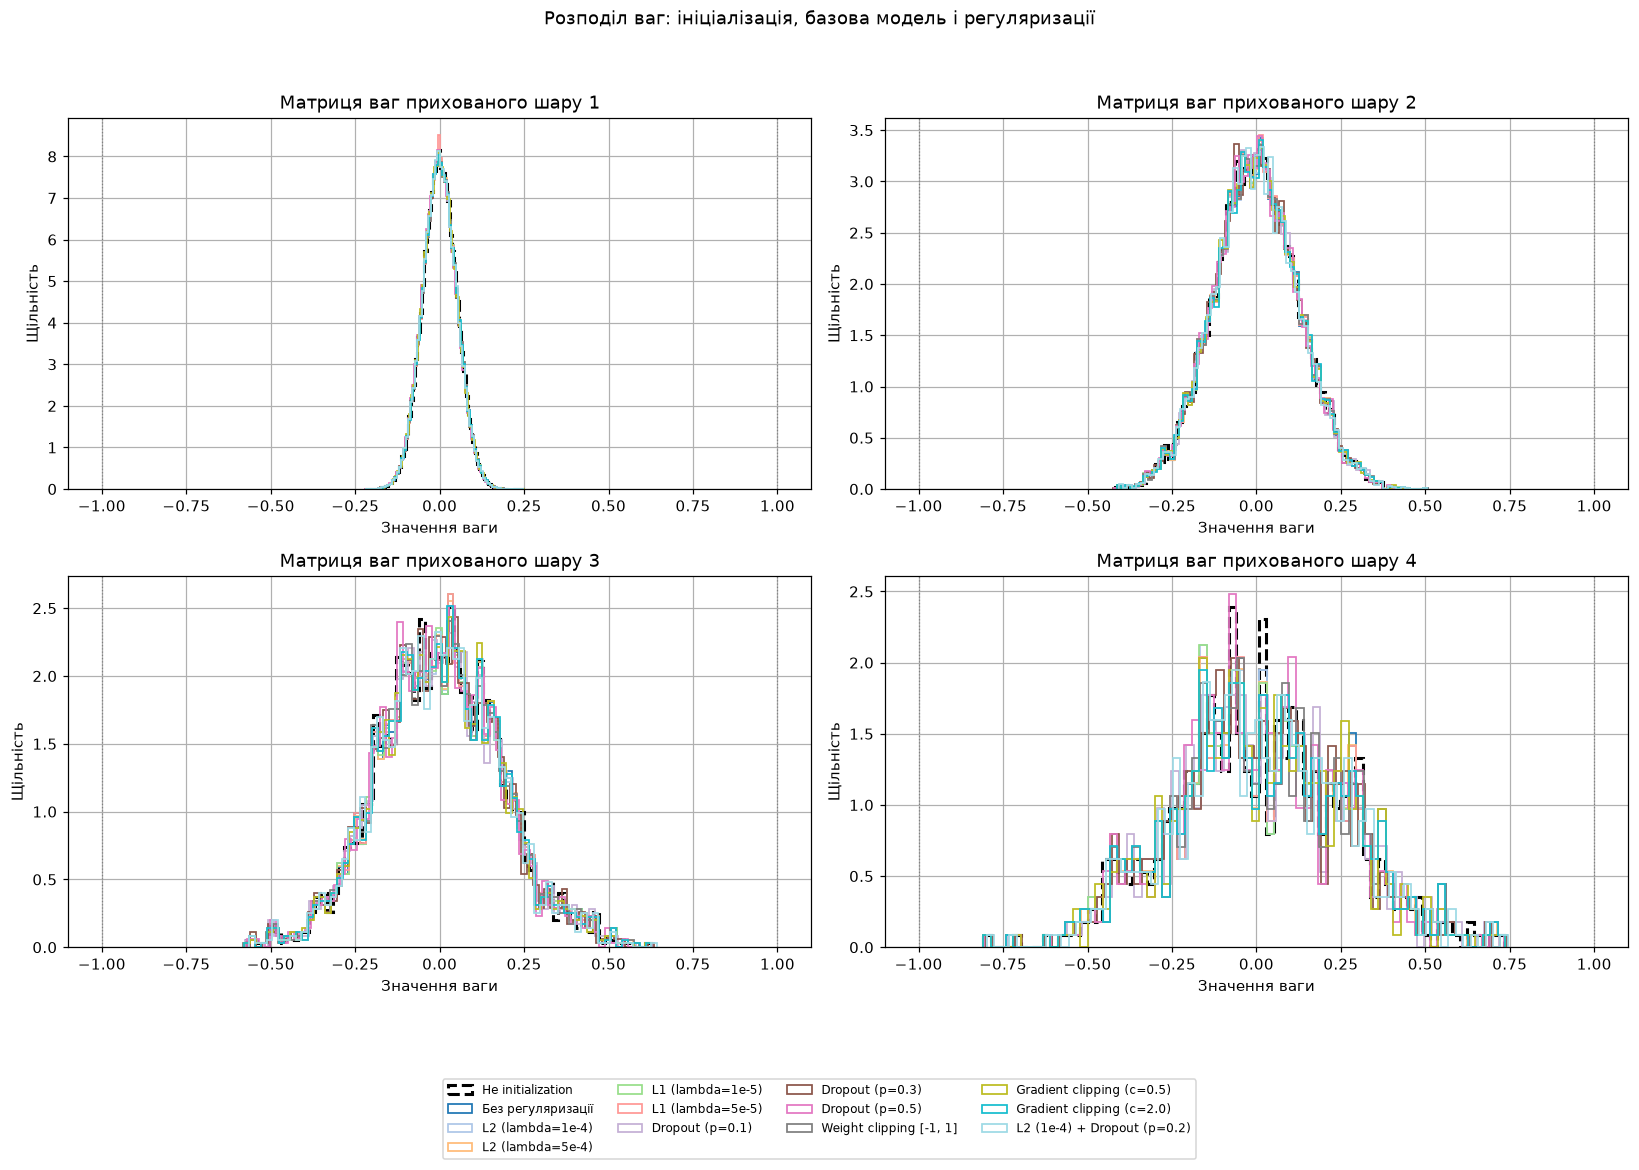

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()
palette = plt.cm.tab20(np.linspace(0, 1, len(models)))
for layer, ax in enumerate(axes):
    ax.hist(INITIAL_WEIGHTS[layer].ravel(), bins=70, density=True, histtype='step',
            linewidth=2.0, linestyle='--', color='black', label='He initialization')
    for color, (name, model) in zip(palette, models.items()):
        ax.hist(model.weights[layer].ravel(), bins=70, density=True, histtype='step',
                linewidth=1.15, color=color, label=name)
    ax.set_title(f'Матриця ваг прихованого шару {layer + 1}')
    ax.set_xlabel('Значення ваги'); ax.set_ylabel('Щільність')
    ax.axvline(-1, color='gray', linestyle=':', linewidth=0.8)
    ax.axvline(1, color='gray', linestyle=':', linewidth=0.8)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.04), fontsize=8)
fig.suptitle('Розподіл ваг: ініціалізація, базова модель і регуляризації', y=1.01)
plt.tight_layout(rect=(0, 0.10, 1, 0.98))
plt.show()

**Висновок до гістограм ваг.** Кожна панель відповідає окремому прихованому шару, а штрихова крива — початковій He-ініціалізації. Порівняння з базовою моделлю показує ефект самого навчання; L1/L2 змінюють концентрацію ваг поблизу нуля, Dropout змінює режим навчання без прямого штрафу на ваги, а weight clipping може утворювати піки біля ±1. Числовий критерій sparsity наведено в таблиці вище.

## 9. Залежність dead neurons від validation accuracy

Кожна точка на діаграмі відповідає одному запуску. Вісь X показує частку мертвих нейронів серед усіх прихованих шарів, вісь Y — validation accuracy; підпис біля точки дає змогу пов'язати її з методом регуляризації.

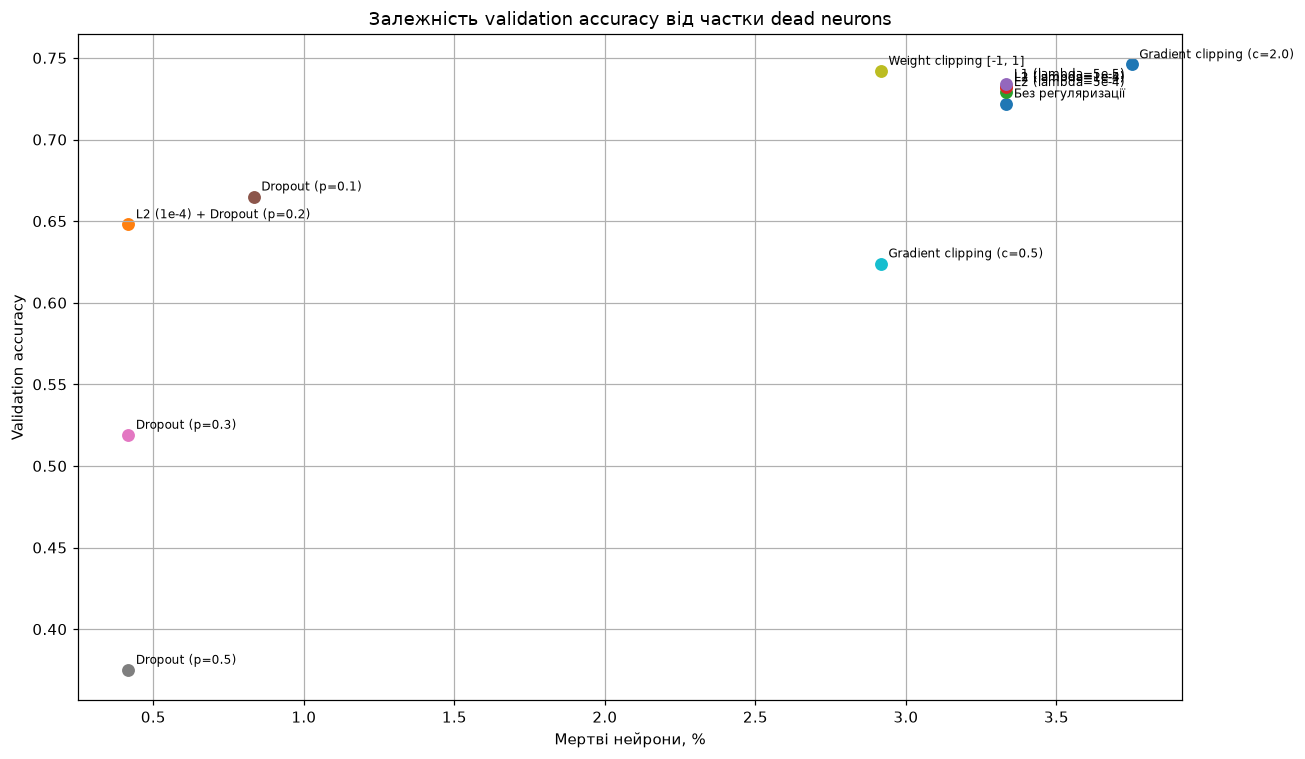

Кореляція між часткою dead neurons і validation accuracy: 0.773


In [14]:
fig, ax = plt.subplots(figsize=(12, 7))
for name, row in results_df.iterrows():
    ax.scatter(row['Dead neurons, %'], row['Validation accuracy'], s=55)
    ax.annotate(name, (row['Dead neurons, %'], row['Validation accuracy']),
                xytext=(5, 4), textcoords='offset points', fontsize=8)
ax.set_xlabel('Мертві нейрони, %')
ax.set_ylabel('Validation accuracy')
ax.set_title('Залежність validation accuracy від частки dead neurons')
plt.tight_layout()
plt.show()
dead_acc_corr = results_df['Dead neurons, %'].corr(results_df['Validation accuracy'])
print(f'Кореляція між часткою dead neurons і validation accuracy: {dead_acc_corr:.3f}')

**Висновок до діаграми.** У цьому запуску спостерігається додатна кореляція між часткою dead neurons і validation accuracy (`r ≈ 0.773`), але це не означає, що мертві нейрони покращують модель: Dropout-конфігурації мають мало dead neurons і водночас нижчу точність, тобто зв’язок пояснюється також видом і силою обмеження. За схожої частки dead neurons accuracy теж відрізняється. Отже, dead-neuron share потрібно трактувати разом із sparsity та loss, а кореляцію — як описову, не причинну.

## 10. Контрольна оцінка на тесті

Після вибору найкращої конфігурації виключно за Validation один раз оцінюємо її та базову модель на Test. Цей результат є фінальною перевіркою узагальнення і не використовується для переобрання регуляризації.

In [15]:
selected_model = models[best_method]
test_comparison = pd.DataFrame({
    'Validation accuracy': [evaluate(baseline_model, X_val, y_val)['accuracy'],
                            evaluate(selected_model, X_val, y_val)['accuracy']],
    'Test accuracy': [evaluate(baseline_model, X_test, y_test)['accuracy'],
                      evaluate(selected_model, X_test, y_test)['accuracy']],
    'Test loss': [evaluate(baseline_model, X_test, y_test)['loss'],
                  evaluate(selected_model, X_test, y_test)['loss']],
}, index=['Без регуляризації', f'Обраний за Validation: {best_method}'])
test_comparison.round(4)

,Validation accuracy,Test accuracy,Test loss
Без регуляризації,0.722,0.734,0.7169
Обраний за Validation: Gradient clipping (c=2.0),0.746,0.745,0.6900


**Висновок до контрольної таблиці.** Test-показники зіставляють базову модель і конфігурацію, обрану за Validation. Якщо напрям зміни якості узгоджується, результат підтримує вибір; невелика різниця між validation та test очікувана через вибіркову мінливість. Test не впливав на налаштування коефіцієнтів.

## 11. Аналіз вимог і відповіді на дослідницькі питання

Підсумовуючи експерименти, оцінюємо, чи допомогла регуляризація саме на цих підмножинах FashionMNIST. Висновки мають спиратися на порівняльну таблицю, гістограми ваг, dead-neuron таблицю та графік, а не лише на одну метрику.

In [16]:
family_best = {}
for family in ['L1', 'L2', 'Dropout', 'Gradient clipping']:
    candidates = [name for name in results_df.index if name.startswith(family)]
    if candidates:
        family_best[family] = max(candidates, key=lambda n: results_df.loc[n, 'Validation accuracy'])
print('Найкраща конфігурація кожного сімейства за Validation:')
for family, name in family_best.items():
    print(f'  {family:20s}: {name:32s} accuracy={results_df.loc[name, "Validation accuracy"]:.4f}')
print(f'Базова: accuracy={baseline_acc:.4f}, '
      f'sparsity={results_df.loc["Без регуляризації", "Sparsity (|w|<0.01), %"]:.2f}%, '
      f'dead={results_df.loc["Без регуляризації", "Dead neurons, %"]:.2f}%')
print(f'Обраний метод: {best_method}; '
      f'Δ accuracy відносно базової={results_df.loc[best_method, "Validation accuracy"] - baseline_acc:+.4f}')

Найкраща конфігурація кожного сімейства за Validation:
  L1                  : L1 (lambda=5e-5)                 accuracy=0.7340
  L2                  : L2 (lambda=1e-4)                 accuracy=0.7320
  Dropout             : Dropout (p=0.1)                  accuracy=0.6650
  Gradient clipping   : Gradient clipping (c=2.0)        accuracy=0.7460
Базова: accuracy=0.7220, sparsity=14.81%, dead=3.33%
Обраний метод: Gradient clipping (c=2.0); Δ accuracy відносно базової=+0.0240


### Відповіді на дослідницькі питання

1. **Чи завжди сильніша регуляризація покращує узагальнення?** Ні. Обмеження знижує перенавчання лише до певної міри; надто велике `λ`, високе `p` або малий поріг градієнта можуть спричинити недонавчання.
2. **Що відрізняє L1 та L2?** L1 через субградієнт `sign(W)` сильніше концентрує параметри біля нуля й може створювати точні нулі; L2 плавно стискає великі значення і зазвичай не створює стільки точних нулів.
3. **Чим Dropout відрізняється від dead neurons?** Dropout тимчасово вимикає активації випадковою маскою лише під час навчання. Dead neuron має нульовий ReLU-вихід для всіх прикладів діагностичної вибірки в режимі inference.
4. **Що показують clipping-експерименти?** Weight clipping безпосередньо обрізає параметри до `[-1,1]`, gradient clipping обмежує норму всього градієнта, але не самі ваги. Їхні розподіли та кількість кліпованих значень у таблиці демонструють цю різницю.
5. **Чи є sparsity синонімом dead neurons?** Ні. Sparsity — частка малих параметрів, а dead neuron — властивість вихідних активацій нейрона на наборі даних. Однакове значення sparsity може відповідати різній кількості мертвих нейронів.

Отримані числові значення й обрана конфігурація наведені в таблицях вище; висновок про метод з найкращою якістю робиться за Validation, а Test використовується лише для заключної оцінки.

## Загальний висновок

У роботі реалізовано багатошарову повнозв’язну нейронну мережу на NumPy з He initialization, ReLU, Softmax, categorical cross-entropy, ручним backpropagation та mini-batch SGD. Коректність похідних перевірена чисельною скінченною різницею, а збереження й відновлення моделі — порівнянням імовірностей із нульовою похибкою. Для однакових підмножин FashionMNIST порівняно L1, L2, Dropout, weight clipping, gradient clipping та комбінацію L2 + Dropout. У цьому запуску базова validation accuracy становила `0.722`, найкращим за Validation виявився gradient clipping `c=2.0` (`0.746`; Test accuracy `0.745`), а сильний Dropout `p=0.5` призвів до недонавчання (`0.375`). Отже, сильніше обмеження не гарантує кращого узагальнення; якість слід аналізувати разом зі sparsity та dead neurons.